# End-To-End ML Projects

**Objective:** Learn end-to-end ml projects with simple, step-by-step examples.

## End-to-End ML Project
This notebook connects the complete workflow: load data, explore, split, preprocess, train, evaluate, save, and predict.

In [1]:
import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

In [2]:
data = pd.read_csv('datasets/breast_cancer.csv')
data.head()

,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,diagnosis
0,12.6704,10.8800,85.5063,619.3016,0.0607,0.0279,benign
1,12.2812,13.0513,74.7648,296.4521,0.1032,0.1111,benign
2,12.1453,17.3817,81.5451,295.3274,0.0955,0.0416,benign
3,13.9326,13.8502,72.4119,327.4327,0.1083,0.0738,benign
4,11.0577,12.9436,82.4523,515.7799,0.0962,0.0972,benign


In [3]:
print(data.shape)
print(data['diagnosis'].value_counts())
data.describe()

(280, 7)
diagnosis
benign       140
malignant    140
Name: count, dtype: int64


,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness
count,280.000000,280.000000,280.000000,280.000000,280.000000,280.000000
mean,14.883669,17.288689,97.384052,701.029588,0.099514,0.118556
std,3.844473,4.652241,26.236474,309.942954,0.017472,0.056614
min,5.478000,5.981500,43.069700,-11.654000,0.053900,-0.022700
25%,11.862650,13.644550,76.364850,443.495625,0.086825,0.079875
50%,14.939150,16.781500,98.055100,702.104300,0.100700,0.116500
75%,17.953100,21.193350,119.719425,950.441300,0.111550,0.163450
max,24.993500,27.929500,160.799400,1455.658000,0.145800,0.242400


In [4]:
X = data.drop(columns=['diagnosis'])
y = data['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

In [5]:
numeric_features = X.columns.tolist()

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features)
])

model = Pipeline([
    ('preprocess', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [6]:
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

      benign       0.97      1.00      0.98        28
   malignant       1.00      0.96      0.98        28

    accuracy                           0.98        56
   macro avg       0.98      0.98      0.98        56
weighted avg       0.98      0.98      0.98        56



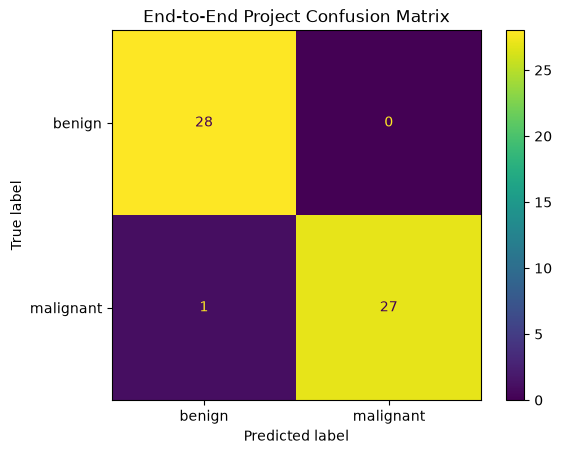

In [7]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions)
plt.title('End-to-End Project Confusion Matrix')
plt.show()

In [8]:
joblib.dump(model, 'breast_cancer_pipeline.joblib')
loaded_model = joblib.load('breast_cancer_pipeline.joblib')

new_prediction = loaded_model.predict(X_test.head(1))
print('Prediction for first test row:', new_prediction[0])

Prediction for first test row: benign


## Try This Yourself
- Replace LogisticRegression with RandomForestClassifier.
- Add cross validation before the final test evaluation.
- Write a short project summary with metric results and next steps.